## ⚙️ Load the GROMACS–PLUMED Environment

Loads the required **compiler, MPI, CUDA, GROMACS, and PLUMED environment** on ACCRE and makes the configured GROMACS–PLUMED installation available within the notebook for subsequent HREMD setup and simulations.

In [ ]:
import sys
!{sys.executable} -m pip install plumed

In [ ]:
import plumed

In [1]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [2]:
load_gmx_plumed()

Notice that we use two temperature groups (protein and solvent). However, when we will do solute tempering, both temperatures will be equal to 300K

## 2a: Setting up scaled Hamiltonians

In [4]:
import os
import re
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

workdir = os.getcwd()

input_gro = os.path.join(workdir, "Prep/b4md.gro")
input_top = os.path.join(workdir, "Prep/protein.top")
input_mdp = os.path.join(workdir, "grompp.mdp")

os.makedirs("2a", exist_ok=True)

# ============================================================
# Generate self-contained topology
# ============================================================

run_cmd(
    f"gmx_mpi grompp "
    f"-f {input_mdp} "
    f"-c {input_gro} "
    f"-p {input_top} "
    f"-pp 2a/processed.top "
    f"-o 2a/test.tpr"
)

# ============================================================
# Mark first molecule atoms with "_"
# ============================================================

in_molecules = False
in_atoms = False
molecule_done = False

with open("2a/processed.top") as f, \
     open("2a/processed_selected.top","w") as ff:

    for l in f:

        if (
            in_atoms
            and not re.match(r" *;.*",l)
            and not re.match(r"\[.*",l)
            and len(l.split()) > 2
        ):

            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)

        else:
            print(l, end="", file=ff)

        if not molecule_done and re.match(r"\[ *moleculetype *\]",l):
            in_molecules = True
            molecule_done = True

        elif in_molecules and re.match(r"\[ *atoms *\]",l):
            in_atoms = True

        elif re.match(r"\[.*",l):
            in_molecules = False
            in_atoms = False

# ============================================================
# Generate scaled topologies
# ============================================================

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 1.0 "
    "< processed_selected.top "
    "> scaled1.0.top"
)

run_cmd(
    "cd 2a && "
    "plumed partial_tempering 0.5 "
    "< processed_selected.top "
    "> scaled0.5.top"
)

print("\n🎉 Finished Exercise 2a.")

gmx_mpi grompp -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/3PRG/grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/3PRG/Prep/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/3PRG/Prep/protein.top -pp 2a/processed.top -o 2a/test.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -772807811

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   275    Protein residues
There are: 12709      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.427 nm between atom 875 and 882

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 310 K

Calculated rlist for 1x1 atom pair-list as 0.935 nm, buffer size 0.035 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

cd 2a && plumed partial_tempering 0.5 < processed_selected.top > scaled0.5.top


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2a.


In [7]:
!diff 2a/scaled1.0.top 2a/scaled0.5.top

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

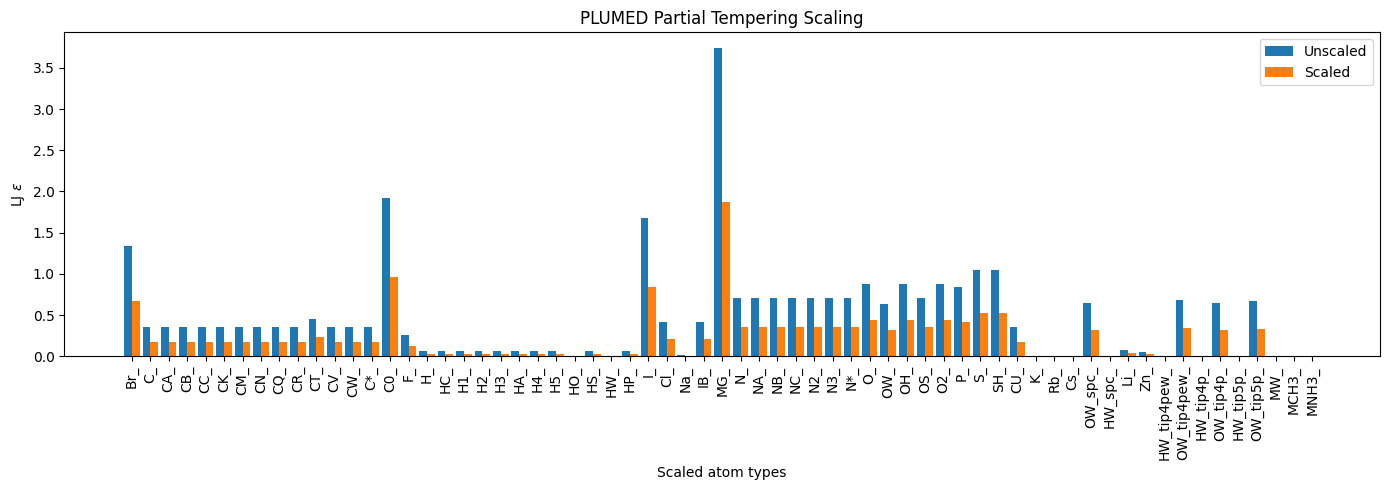

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def read_scaled_eps(topfile):

    rows = []

    with open(topfile) as f:

        for line in f:

            if "scaled" not in line:
                continue

            line = line.split(";")[0]

            parts = line.split()

            if len(parts) < 7:
                continue

            atom = parts[0]
            eps = float(parts[6])

            rows.append([atom, eps])

    return pd.DataFrame(
        rows,
        columns=["atom","epsilon"]
    )

top1 = read_scaled_eps("2a/scaled1.0.top")
top05 = read_scaled_eps("2a/scaled0.5.top")

df = top1.merge(
    top05,
    on="atom",
    suffixes=("_1.0","_0.5")
)

x = np.arange(len(df))

width = 0.42

plt.figure(figsize=(14,5))

plt.bar(
    x-width/2,
    df["epsilon_1.0"],
    width,
    label="Unscaled"
)

plt.bar(
    x+width/2,
    df["epsilon_0.5"],
    width,
    label="Scaled"
)

plt.xticks(
    x,
    df["atom"],
    rotation=90
)

plt.ylabel(r"LJ $\epsilon$")
plt.xlabel("Scaled atom types")

plt.title(
    "PLUMED Partial Tempering Scaling"
)

plt.legend()

plt.tight_layout()
plt.show()

# 2b: Sanity check on generated topologies

In [9]:
import os
import subprocess

def run_cmd(cmd):
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

# ============================================================
# Exercise 2b: short reference trajectory sanity check
# ============================================================

os.makedirs("2b", exist_ok=True)

run_cmd(
    "cd 2b && "
    "gmx_mpi grompp "
    "-f ../grompp.mdp "
    "-c ../b4md.gro "
    "-p ../topol.top "
    "-o topol.tpr"
)

run_cmd(
    "cd 2b && "
    "gmx_mpi mdrun "
    "-deffnm topol "
    "-nsteps 5000"
)

print("\n🎉 Finished Exercise 2b reference trajectory.")

cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p ../topol.top -o topol.tpr


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Setting the LD random seed to -138944645

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


🎉 Finished Exercise 2b reference trajectory.


### 🔍 Exercise 2b — Sanity Check

Recompute energies for the **same trajectory** using:

1. Original topology
2. `partial_tempering(1.0)` topology

```text
Same coordinates
+
Different topology files
↓
Compare energies
```



In [10]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

os.makedirs("2b/rerun0",exist_ok=True)
os.makedirs("2b/rerun1",exist_ok=True)

run("cp 2a/processed_selected.top 2b/processed_selected.top")

run("cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr")

run("cd 2b/rerun0 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr")

run('cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

run("cd 2b/rerun1 && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr")

run('cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished sanity check")

cp 2a/processed_selected.top 2b/processed_selected.top
cd 2b && plumed partial_tempering 1.0 < processed_selected.top > topol_scaled1.0.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled1.0.top -o topol_scaled1.0.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.60
Number of degrees of freedom in T-Coupling group non-Protein is 70668.41

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Some of these pro-drug messages come from popular cu

Setting the LD random seed to -1107853895

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dim

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun0
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol.tpr

Reading file ../topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the GPU
Using 1 MPI proce

cd 2b/rerun0 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun0
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "Considering the current sad state of our computer programs, software development is clearly still a


Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3408.49         --    107.453    43.4456  (kJ/mol)
Angle                       9285.69         --    85.8944    32.7383  (kJ/mol)
Proper Dih.                 10628.1         --    48.1764   -94.8809  (kJ/mol)
Per. Imp. Dih.              524.923         --    25.4906   -15.2051  (kJ/mol)
LJ-14                       4431.41         --    30.7287   -51.5654  (kJ/mol)
Coulomb-14                  53330.9         --    69.4954    -72.582  (kJ/mol)
LJ (SR)                     67238.1         --    1053.53    1087.54  (kJ/mol)
Disper. corr.              -7501.27         --          0          0  (kJ/mol)
Coulomb (SR)                -652418         --    1727.63   -3232.25  (kJ/mol)
Coul. recip.             

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun1
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled1.0.tpr

Reading file ../topol_scaled1.0.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 80, rlist from 0.9 to 1.039


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the G

cd 2b/rerun1 && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no

Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3408.49         --    107.453    43.4456  (kJ/mol)
Angle                       9285.69         --    85.8944    32.7383  (kJ/mol)
Proper Dih.                 10628.1         --    48.1764   -94.8809  (kJ/mol)
Per. Imp. Dih.              524.923         --    25.4906   -15.2051  (kJ/mol)
LJ-14                       4431.41         --    30.7287   -51.5654  (kJ/mol)
Coulomb-14                  53330.9         --    69.4954    -72.582  (kJ/mol)
LJ (SR)                     67238.1         --    1053.53    1087.57  (kJ/mol)
Disper. corr.              -7501.27         --          0          0  (kJ/mol)
Coulomb (SR)                -652

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun1
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "It's hard to ignore 12 orders of magnitude" (John Urbanic)



Expected:

```text
Original − Scaled(1.0) ≈ 0
```

Tiny numerical noise is normal.

Confirms:

✅ `partial_tempering` edited the topology correctly  
✅ No force field terms were accidentally changed  
✅ Hamiltonian remains unchanged at λ = 1.0

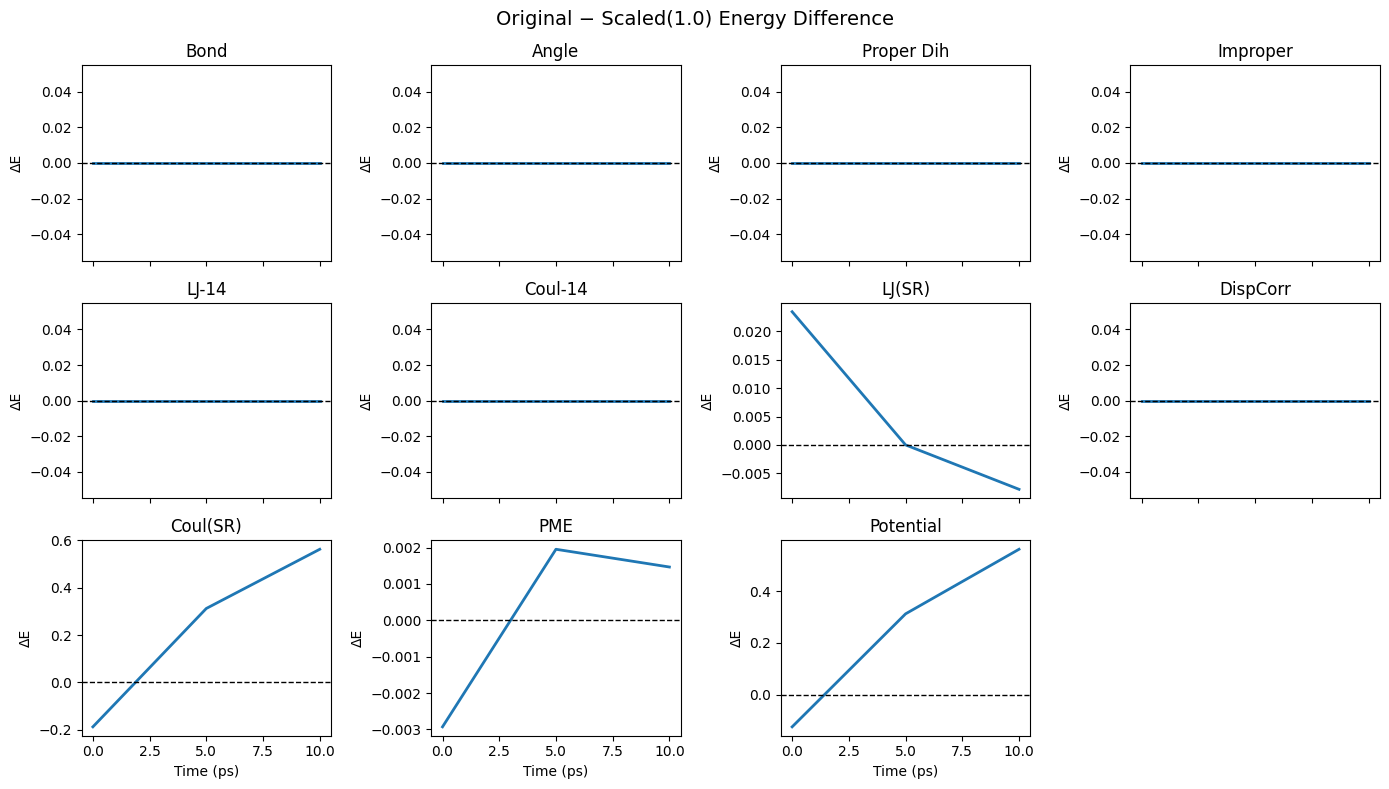

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun1/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:, 0]
diff = ene.iloc[:, 1:].values - ene_scaled.iloc[:, 1:].values

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
axes = axes.flatten()

for i, name in enumerate(labels):
    axes[i].plot(time, diff[:, i], lw=2)
    axes[i].axhline(0, color="black", ls="--", lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels), len(axes)):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Scaled(1.0) Energy Difference", fontsize=14)
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Select all atoms (protein + water + ions), apply:

```text
partial_tempering(0.1)
```

Then recompute energies on the **same trajectory** using `-rerun`.

Expected:

```text
Dihedral ≈ 0.1×
LJ ≈ 0.1×
Coulomb ≈ 0.1×
```

Confirms:

✅ Whole-system Hamiltonian scaling works correctly

In [12]:
import os
import re
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2b/rerun_whole", exist_ok=True)

# mark ALL moleculetype [ atoms ] sections with "_"
with open("2a/processed.top") as f, open("2b/processed_selected_whole.top", "w") as ff:

    in_atoms = False

    for l in f:

        if in_atoms and not re.match(r" *;.*", l) and not re.match(r"\[.*", l) and len(l.split()) > 2:
            ll = l.split()
            ll[1] = ll[1] + "_"
            print(" ".join(ll), file=ff)
        else:
            print(l, end="", file=ff)

        if re.match(r"\[ *atoms *\]", l):
            in_atoms = True
        elif re.match(r"\[.*", l):
            in_atoms = False

run("cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top")

run("cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr")

run("cd 2b/rerun_whole && gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr")

run('cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no')

print("🎉 Finished whole-system 0.1 scaling sanity check")

cd 2b && plumed partial_tempering 0.1 < processed_selected_whole.top > topol_scaled_whole0.1.top
cd 2b && gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b
Command line:
  gmx_mpi grompp -f ../grompp.mdp -c ../b4md.gro -p topol_scaled_whole0.1.top -o topol_scaled_whole0.1.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.60
Number of degrees of freedom in T-Coupling group non-Protein is 70668.41

NOTE 2 [file ../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Never replicate a successful experiment.

Setting the LD random seed to 1979625371

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.900 nm, buffer size 0.000 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun_whole
Command line:
  gmx_mpi mdrun -rerun ../topol.xtc -s ../topol_scaled_whole0.1.tpr

Reading file ../topol_scaled_whole0.1.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 100, rlist from 0.9 to 0.9


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all 

cd 2b/rerun_whole && echo "1 2 3 4 5 6 7 8 9 10 11" | gmx_mpi energy -xvg no

Statistics over 5001 steps [ 0.0000 through 10.0000 ps ], 11 data sets
All statistics are over 3 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Bond                        3408.49         --    107.453    43.4456  (kJ/mol)
Angle                       9285.69         --    85.8944    32.7383  (kJ/mol)
Proper Dih.                 1062.81         --    4.81766   -9.48804  (kJ/mol)
Per. Imp. Dih.              52.4923         --    2.54906   -1.52051  (kJ/mol)
LJ-14                       443.141         --    3.07285   -5.15662  (kJ/mol)
Coulomb-14                   5333.1         --    6.94964   -7.25879  (kJ/mol)
LJ (SR)                     6723.82         --    105.353    108.745  (kJ/mol)
Disper. corr.              -750.127         --          0          0  (kJ/mol)
Coulomb (SR)               

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2b/rerun_whole
Command line:
  gmx_mpi energy -xvg no

Opened ener.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential     

Last energy frame read 2 time   10.000            

GROMACS reminds you: "Weaseling out of things is important to learn. It's what separates us from the animals... exce

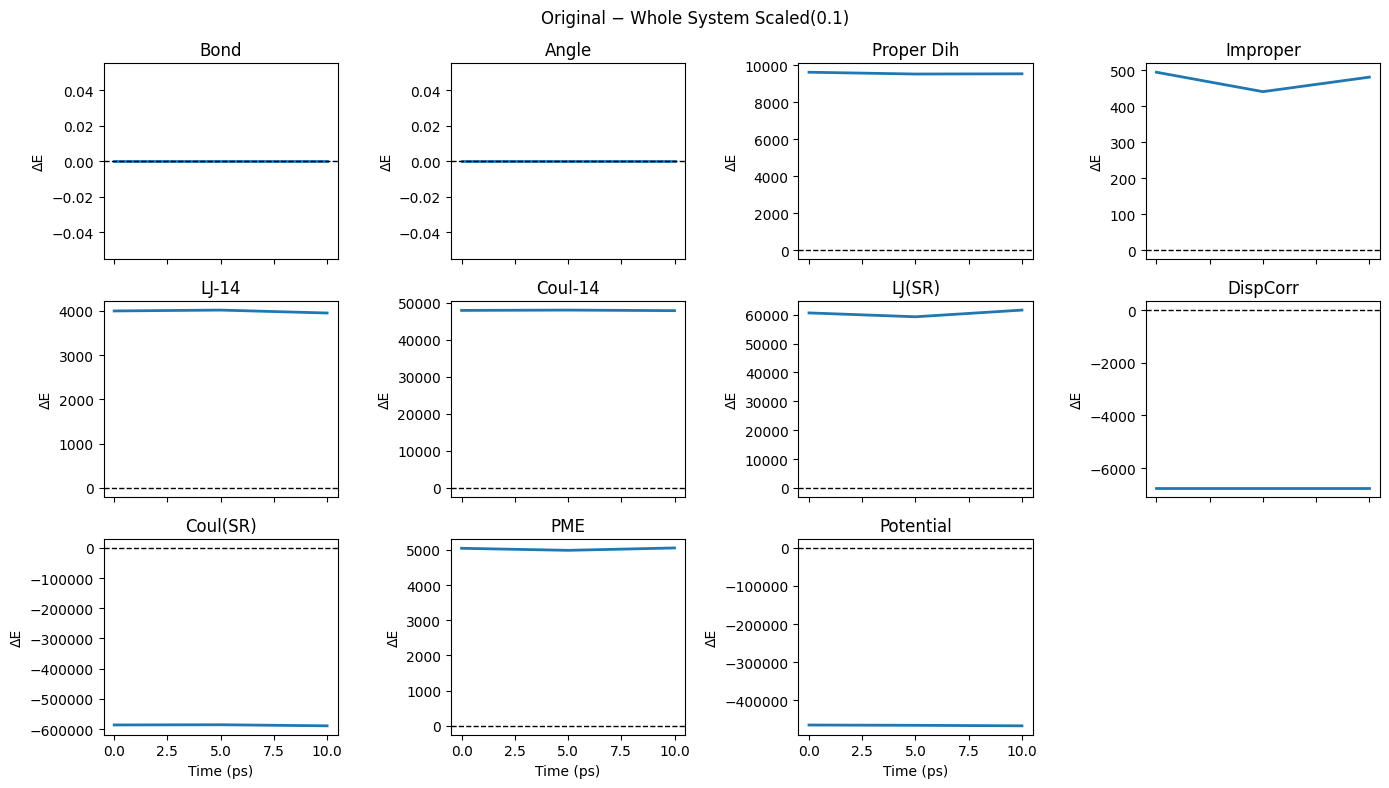

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

labels = [
    "Bond", "Angle", "Proper Dih", "Improper",
    "LJ-14", "Coul-14", "LJ(SR)", "DispCorr",
    "Coul(SR)", "PME", "Potential"
]

ene = pd.read_csv("2b/rerun0/energy.xvg", header=None, sep=r"\s+")
ene_scaled = pd.read_csv("2b/rerun_whole/energy.xvg", header=None, sep=r"\s+")

time = ene.iloc[:,0]
diff = ene.iloc[:,1:].values - ene_scaled.iloc[:,1:].values

fig, axes = plt.subplots(3,4,figsize=(14,8),sharex=True)
axes = axes.flatten()

for i,name in enumerate(labels):
    axes[i].plot(time,diff[:,i],lw=2)
    axes[i].axhline(0,color="black",ls="--",lw=1)
    axes[i].set_title(name)
    axes[i].set_ylabel("ΔE")

for j in range(len(labels),12):
    axes[j].axis("off")

for ax in axes[-4:]:
    ax.set_xlabel("Time (ps)")

fig.suptitle("Original − Whole System Scaled(0.1)")
plt.tight_layout()
plt.show()

### 🔍 Whole-System Scaling Check

Applied:

```text
partial_tempering(0.1)
```

Observed:

✅ Bond / Angle unchanged  
✅ Dihedral, LJ, Coulomb scaled  
✅ Potential changed strongly  

Inference:

```text
Whole-system Hamiltonian scaling works correctly
```

# 2c: Sanity check on replica-exchange implementation

Once we know the topologies are fine, we should double check if the gromacs+plumed implementation is correctly calculating the acceptance.

We run a replica exchange simulation with 2 replicas with identical Hamiltonians. Acceptance shoud be 1.

In [15]:
import os
import subprocess

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd)
    subprocess.run(cmd, shell=True, executable="/bin/bash", check=True)

os.makedirs("2c/rep0", exist_ok=True)
os.makedirs("2c/rep1", exist_ok=True)

open("2c/plumed.dat", "w").close()

run("cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top")

run("cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr")

run("cd 2c/rep1 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr")

run("cd 2c && mpirun --oversubscribe -np 2 gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1")

cp 2b/topol_scaled1.0.top 2c/topol_scaled1.0.top
cd 2c/rep0 && gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2c/rep0
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../../topol.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.60
Number of degrees of freedom in T-Coupling group non-Protein is 70668.41

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 2 NOTEs

GROMACS reminds you: "I never see what has been done; I only see what r

Setting the LD random seed to -40978

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensio

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2c/rep1
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p ../topol_scaled1.0.top -o topol.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 11021.60
Number of degrees of freedom in T-Coupling group non-Protein is 70668.41

NOTE 2 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 2 NOTEs

GROMACS reminds you: "I'll Match Your DNA" (Red Hot Chili Pepper

Setting the LD random seed to -672137738

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2c
Command line:
  gmx_mpi mdrun -nsteps 1000 -multidir rep0 rep1 -replex 200 -hrex -plumed ../plumed.dat -nb cpu -pme cpu -bonded cpu -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environm

In [16]:
logfile = "2c/rep0/md.log"

patterns = ["Repl", "dplumed"]

with open(logfile) as f:
    lines = f.readlines()

for pattern in patterns:
    print(f"\n===== {pattern} =====")
    for line in lines:
        if pattern == "dplumed":
            if line.startswith("dplumed"):
                print(line.rstrip())
        else:
            if pattern in line:
                print(line.rstrip())


===== Repl =====
Initializing Replica Exchange
Repl  There are 2 replicas:
Replica-exchange molecular dynamics method for protein folding
Replica exchange in temperature
Replica exchange interval: 200
Replica random seed: 1073642991
Replica exchange information below: ex and x = exchange, pr = probability
Replica exchange at step 200 time 0.40000
Repl 0 <-> 1  dE_term =  0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 400 time 0.80000
Repl ex  0    1
Repl pr
Replica exchange at step 600 time 1.20000
Repl 0 <-> 1  dE_term =  0.000e+00 (kT)
Repl ex  0 x  1
Repl pr   1.0
Replica exchange at step 800 time 1.60000
Repl ex  0    1
Repl pr
Replica exchange statistics
Repl  4 attempts, 2 odd, 2 even
Repl  average probabilities:
Repl     0    1
Repl      1.0
Repl  number of exchanges:
Repl     0    1
Repl        2
Repl  average number of exchanges:
Repl     0    1
Repl      1.0
Repl        Empirical Transition Matrix
Repl       1       2
Repl  0.5000  0.5000  0
Repl  0.50

### 🔍 Replica Exchange Sanity Check

Observed:

✅ Exchange probability = 1.0  
✅ Exchanges accepted every attempt  
✅ dE_term ≈ 0 kT  
✅ dplumed ~ 10⁻⁶–10⁻⁸ kT  

Inference:

```text
Replica exchange acceptance is implemented correctly
```

Identical Hamiltonians give ~100% acceptance as expected.

## 🧪 Test λ Spacing and Potential-Energy Overlap

Prepares **30 λ replicas from 1.00 to 0.30** to test whether neighboring replicas show sufficient **potential-energy overlap** and to evaluate whether the chosen λ spacing is suitable for efficient replica exchange.

In [17]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_"):
            os.environ.pop(k,None)

def run(cmd):
    clean_env()
    print(cmd,flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00,0.30,30)

os.makedirs("2d",exist_ok=True)

def prep_lambda(lam):

    label = int(round(lam*100))
    path = f"2d/lambda_{label}"

    os.makedirs(path,exist_ok=True)

    run(f"cp 2a/processed_selected.top {path}/processed_selected.top")

    run(
        f"cd {path} && "
        f"plumed partial_tempering {lam:.3f} < processed_selected.top > topol.top"
    )

    run(
        f"cd {path} && "
        f"gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1"
    )

    return f"✅ lambda_{label}"

workers=len(lambdas)

with ThreadPoolExecutor(max_workers=workers) as executor:

    futures=[
        executor.submit(prep_lambda,lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        print(future.result(),flush=True)

print("🎉 Finished prep")

cp 2a/processed_selected.top 2d/lambda_100/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_98/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_95/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_42/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_93/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_90/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_88/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_86/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_83/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_81/processed_selected.top
cp 2a/processed_selected.top 2d/lambda_78/processed_selected.top
cd 2d/lambda_98 && plumed partial_tempering 0.976 < processed_selected.top > topol.top
cd 2d/lambda_95 && plumed partial_tempering 0.952 < processed_selected.top > topol.top
cd 2d/lambda_42 && plumed partial_tempering 0.421 < processed_selected.top > topol.top
cd 2d/lambda_93 && plum

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98
Command line:
  gmx_mpi grompp -c ../../b4md.gro -f ../../grompp.mdp -p topol.top -o topol.tpr -maxwarn 1

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file ../../grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5

NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 0.060256
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file topol.top, line 57639]:
  Yo

Setting the LD random seed to -11157

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------




NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

GROMACS reminds you: "There is an infinite set A that is not too big." (John von Neumann)



Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x64, spacing 0.118 0.115 0.113

Estimate for the relative computational load of the PME mesh part: 0.30
Setting the LD random seed to -23855451

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighb

...

Setting the LD random seed to -1107567235

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------

Setting the LD random seed to -88089265

Generated 8515 of the 8515 non-bonded parameter combinations

Generated 8515 of the 8515 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 


NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 1.322179
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file topol.top, line 57639]:
  You are using Ewald electrostatics in a system with net charge. This can
  lead to severe artifacts, such as ions moving into regions with low
  dielectric, due to the uniform background charge. We suggest to
  neutralize your system with counter ions, possibly in combination with a
  physiological salt concentration.


NOTE 2 [file topol.top, line 57639]:
  System has non-zero total charge: 1.238365
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file topol.top, line 57639]:
  You are using Ewald electrostatics in a system with net charge. This 

Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x64, spacing 0.118 0.115 0.113

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance


GROMACS reminds you: "There is an infinite set A that is not too big." (John von Neumann)


NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

NOTE 3 [file ../../grompp.mdp]:
  This run will generate roughly 3835 Mb of data


There were 3 NOTEs

There was 1 WARNING

GROMACS reminds you: "There is an infin

Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 300 K

Calculated rlist for 1x1 atom pair-list as 0.934 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 0.900 nm, buffer size 0.000 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 56x72x64, spacing 0.118 0.115 0.113

Estimate for the relative computational load of the PME mesh part: 0.30
Analysing residue names:
There are:   271    Protein residues
There are: 11776      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.430 nm between atom 2262 and 2270

Determining Verlet buffer for a tolerance

## 🚀 Run 10 ns HREMD Test Across All λ Replicas

Runs all **30 λ replicas simultaneously for 10 ns** using GROMACS `-multidir`, distributed across four GPUs. The resulting trajectories are used to evaluate **potential-energy overlap between neighboring λ replicas** and refine the λ spacing for the production HREMD setup.

In [18]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:

    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-nsteps 5000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Finished all lambdas")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -nsteps 5000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading 

🎉 Finished all lambdas


## 📊 Assess Structural Stability Across λ Replicas

Calculates **RMSD** and **radius of gyration (Rg)** for all **30 λ replicas** from the 10 ns HREMD test. Because stronger tempering at lower λ values can destabilize the protein, these measurements are used to determine whether the replicas remain structurally reasonable and to identify λ values that produce excessive unfolding or expansion. Together with the **potential-energy overlap**, this helps define an appropriate λ range and spacing for the production HREMD simulation.

In [19]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_lambda(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(workdir, "2d", f"lambda_{label}")

    tpr = os.path.join(replica_dir, "topol.tpr")
    xtc = os.path.join(replica_dir, "topol.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ lambda_{label}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ lambda_{label}: missing topol.xtc"

    print(f"▶️ Starting lambda_{label}", flush=True)

    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished lambda_{label}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambdas at once
max_workers = len(lambdas)

# ============================================================
# Run analysis in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_lambda, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting lambda_95
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_95/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_95/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_95/gyration.xvg"
▶️ Starting lambda_88
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/gyration.xvg"
▶️ Starting lambda_86
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary

               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi gyrate -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/gyration.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group  

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/rmsd.xvg"
Selected 1: 'Protein'


Last frame       2000 time 10000.000   
Reading frame    1500 time 7500.000   
GROMACS reminds you: "This really is a pretty scene, could you ask your kid to smile please?" (Joe Jackson)

Reading frame    1500 time 7500.000   

printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/rmsd.xvg"
Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/rmsd.xvg"


...

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_47
✅ Finished lambda_83
✅ Finished lambda_76
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_90


Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   
Reading frame    1900 time 9500.000   
GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)


GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   
Reading frame    1900 time 9500.000   
GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You F

✅ Finished lambda_57
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_59
✅ Finished lambda_44
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_64
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_30
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_71
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_73
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_66
Selected 1: 'Protein'
Selected 1: 'Protein'


Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)


GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)


GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)


GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   
Last frame       2000 time 10000.000   

GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)


GROMACS reminds you: "You Think That You're Bigger When You Fill the Void" (Urban Dance Squad)

Last frame       2000 time 10000.000   
L

✅ Finished lambda_35
✅ Finished lambda_42
✅ Finished lambda_32
✅ Finished lambda_40
✅ Finished lambda_52
✅ Finished lambda_61
✅ Finished lambda_49
✅ Finished lambda_78

🎉 Finished all parallel Rg and RMSD analysis.


## 📈 Visualize Structural Stability Across λ Replicas

Plots **RMSD** and **radius of gyration (Rg)** for all valid λ replicas over the 10 ns HREMD test. This provides a direct visual check for increasing structural distortion or expansion at lower λ values and helps identify an appropriate tempering range for production HREMD.

Valid lambdas: [100, 98, 95, 93, 90, 88, 86, 83, 81, 78, 76, 73, 71, 69, 66, 64, 61, 59, 57, 54, 52, 49, 47, 44, 42, 40, 37, 35, 32, 30]


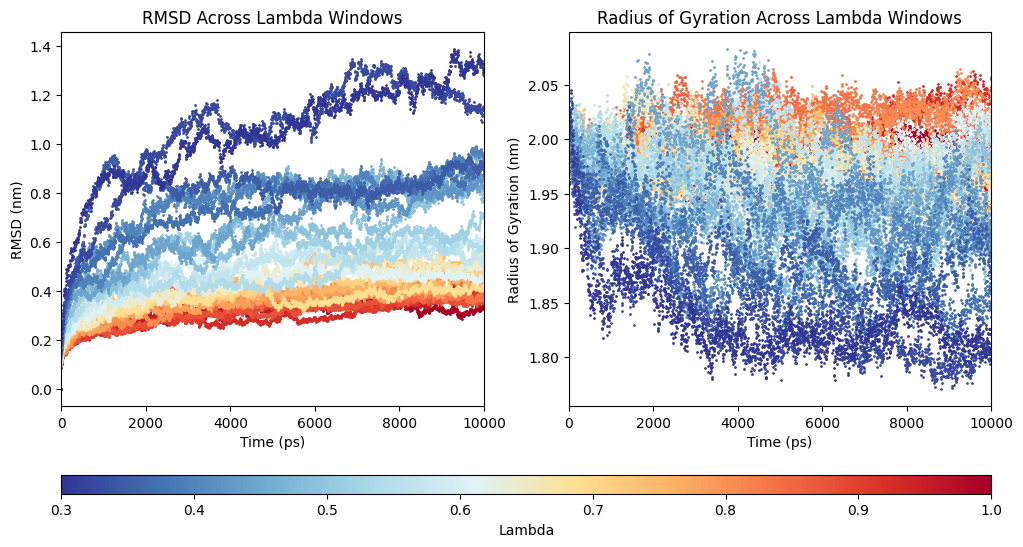

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# LAMBDAS
# =========================================================

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

norm = Normalize(vmin=min(lambdas), vmax=max(lambdas))

main_dir = "2d"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_lambdas = []
valid_labels = []

for lam, label in zip(lambdas, labels):

    rmsd_file = os.path.join(main_dir, f"lambda_{label}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"lambda_{label}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for lambda_{label}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_lambdas.append(lam)
    valid_labels.append(label)

print("Valid lambdas:", valid_labels)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Lambda Windows")
ax1.set_xlim(0, 10000)

# =========================================================
# Rg
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Lambda Windows")
ax2.set_xlim(0, 10000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Lambda")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## ⚡ Extract Potential Energy Across λ Replicas

Extracts the **potential energy time series** from each of the 30 λ replicas. These distributions are used to assess **potential-energy overlap between neighboring λ windows**, helping determine whether the chosen λ spacing is suitable for efficient replica exchange.

In [21]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  2d/lambda_XXX/topol.edr
#   Output: 2d/lambda_XXX/potential.xvg
# ============================================================

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(main_dir, f"lambda_{label}")

    edr_file = os.path.join(replica_dir, "topol.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ lambda_{label}: missing topol.edr"

    print(f"▶️ Starting lambda_{label}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ lambda_{label}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "2d")

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambda windows at once
max_workers = len(lambdas)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all lambda windows.")

▶️ Starting lambda_100
▶️ Starting lambda_98
▶️ Starting lambda_93
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/potential.xvg" -xvg none
▶️ Starting lambda_90
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/potential.xvg" -xvg none
▶️ Starting lambda_95
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_90/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_90/potential.xvg" -xvg none
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_93/topol.edr" -o "/panfs/accrepfs.vampire/da

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       


Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -507010         64    773.182   -332.605  (kJ/mol)


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -505769         50    776.413   -292.939  (kJ/mol)

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -492198         14    773.453    32.3206  (kJ/mol)
✅ lambda_100: potential.xvg written, 1001 frames


...


Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -475346         19    754.959    14.7275  (kJ/mol)

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -471980         12    749.738    73.8885  (kJ/mol)
✅ lambda_37: potential.xvg written, 1001 frames
✅ lambda_30: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
----------------------------------

Last energy frame read 1000 time 10000.000         
Reading energy frame    700 time 7000.000         
GROMACS reminds you: "Fifty years of programming language research, and we end up with C++???" (Richard O'Keefe)

Last energy frame read 1000 time 10000.000         
Reading energy frame    700 time 7000.000         
GROMACS reminds you: "Fifty years of programming language research, and we end up with C++???" (Richard O'Keefe)

Last energy frame read 1000 time 10000.000         

GROMACS reminds you: "Fifty years of programming language research, and we end up with C++???" (Richard O'Keefe)

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_42/topol.edr -o /

✅ lambda_73: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -478865         21    755.334    70.4393  (kJ/mol)
✅ lambda_57: potential.xvg written, 1001 frames
✅ lambda_64: potential.xvg written, 1001 frames
✅ lambda_81: potential.xvg written, 1001 frames
✅ lambda_42: potential.xvg written, 1001 frames
✅ lambda_95: potential.xvg written, 1001 frames

Statistics over 5000001 steps [ 0.0000 through 10000.0000 ps ], 1 data sets
All statistics are over 50001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -487294         20    762.303   -121.121  (kJ/mol)
✅ lambda_35: potential.xvg

Last energy frame read 1000 time 10000.000         

GROMACS reminds you: "Chemistry: It tends to be a messy science." (Gunnar von Heijne, former chair of the Nobel Committee for chemistry)



✅ lambda_61: potential.xvg written, 1001 frames

🎉 Finished extracting potential energy for all lambda windows.


## ⚡ Evaluate Potential-Energy Overlap Between λ Replicas

Plots the **potential-energy distributions** from the 10 ns HREMD test for all 30 λ replicas. Overlap between neighboring distributions is used to evaluate whether the **λ spacing provides sufficient energetic overlap for replica exchange** and to guide selection of the final λ schedule.

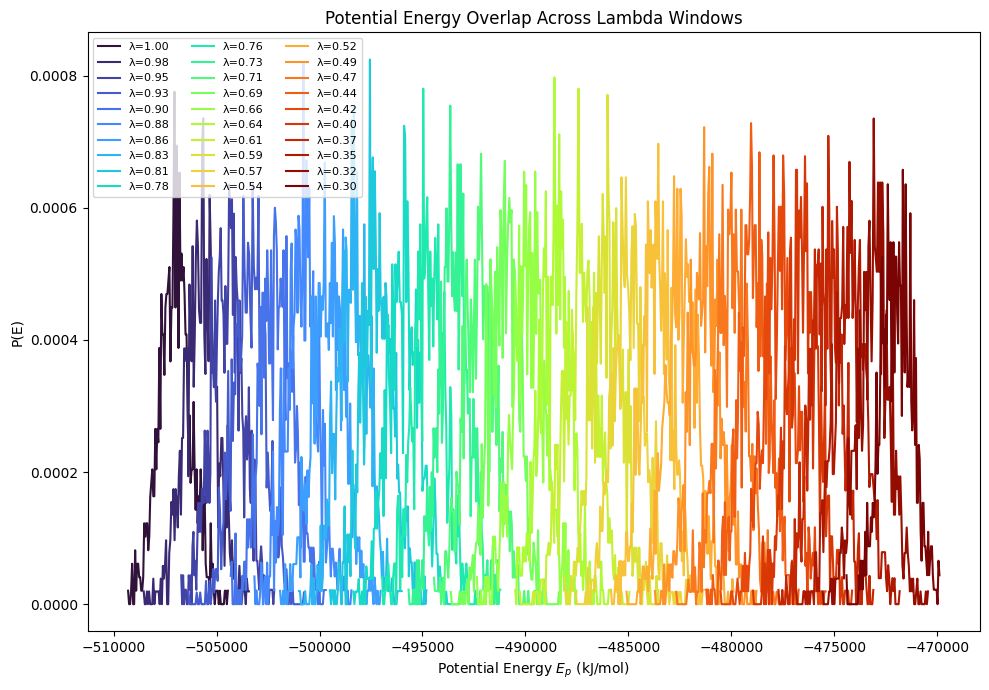

In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  2d/lambda_XXX/potential.xvg
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(main_dir, f"lambda_{label}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap Across Lambda Windows")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### 🔎 Initial Assessment

From the initial 10 ns test, the **potential-energy distributions are noisy and their overlap is difficult to evaluate clearly**, while the **RMSD and Rg trajectories have not yet reached stable plateaus**. Based on these results, the simulations will be extended and the same analyses repeated after additional sampling.
*******

## ⏳ Extend the HREMD Test to 100 ns

Continues all **30 λ replicas from the existing checkpoints** for an additional **90 ns**, bringing the total sampling time to **100 ns per replica**. The extended trajectories will be used to reassess **RMSD, radius of gyration, and potential-energy overlap** after longer sampling.

In [ ]:
import os
import subprocess
import numpy as np

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

lambdas = np.linspace(1.00, 0.30, 30)

dirs = []

for lam in lambdas:
    label = int(round(lam * 100))
    dirs.append(f"2d/lambda_{label}")

multidir = " ".join(dirs)

run(
    f"mpirun --oversubscribe -np 30 "
    f"gmx_mpi mdrun "
    f"-multidir {multidir} "
    f"-deffnm topol "
    f"-cpi topol.cpt "
    f"-append "
    f"-nsteps 45000000 "
    f"-nb gpu "
    f"-pme gpu "
    f"-bonded gpu "
    f"-gputasks "
    f"0000000000000000"
    f"1111111111111111"
    f"22222222222222"
    f"33333333333333 "
    f"-pin auto "
    f"-ntomp 1"
)

print("🎉 Continued all lambdas by 90 ns")

mpirun --oversubscribe -np 30 gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi mdrun -multidir 2d/lambda_100 2d/lambda_98 2d/lambda_95 2d/lambda_93 2d/lambda_90 2d/lambda_88 2d/lambda_86 2d/lambda_83 2d/lambda_81 2d/lambda_78 2d/lambda_76 2d/lambda_73 2d/lambda_71 2d/lambda_69 2d/lambda_66 2d/lambda_64 2d/lambda_61 2d/lambda_59 2d/lambda_57 2d/lambda_54 2d/lambda_52 2d/lambda_49 2d/lambda_47 2d/lambda_44 2d/lambda_42 2d/lambda_40 2d/lambda_37 2d/lambda_35 2d/lambda_32 2d/lambda_30 -deffnm topol -cpi topol.cpt -append -nsteps 45000000 -nb gpu -pme gpu -bonded gpu -gputasks 000000000000000011111111111111112222222222222233333333333333 -pin auto -ntomp 1

Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file topol.tpr, VERSION 2023.5-plumed_2.9.2 (si

## 🔧 Complete Unfinished Replicas to 100 ns

Some λ replicas did not complete the full **100 ns simulation**. This step checks the checkpoint time for each replica, identifies those below 100 ns, and continues only the unfinished simulations until they reach 100 ns, while completed replicas are skipped.

In [8]:
import os
import re
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

TARGET_PS = 100000.0
DT_PS = 0.002

MAX_PARALLEL = 4
GPU_IDS = [0, 1, 2, 3]

lambdas = np.linspace(1.00, 0.30, 30)

def get_cpt_time_ps(cpt):
    out = subprocess.check_output(
        f"gmx_mpi check -f {cpt}",
        shell=True,
        executable="/bin/bash",
        text=True,
        stderr=subprocess.STDOUT
    )

    m = re.search(r"time\s+([\d\.]+)", out)

    if not m:
        return None

    return float(m.group(1))

def run_one_lambda(d, nsteps, gpu_id):
    cmd = (
        f"cd {d} && "
        f"CUDA_VISIBLE_DEVICES={gpu_id} "
        f"mpirun --oversubscribe -np 1 "
        f"gmx_mpi mdrun "
        f"-deffnm topol "
        f"-cpi topol.cpt "
        f"-append "
        f"-nsteps {nsteps} "
        f"-nb gpu "
        f"-pme gpu "
        f"-bonded gpu "
        f"-pin auto "
        f"-ntomp 1 "
        f"> continue_to_100ns.log 2>&1"
    )

    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

    return d

jobs = []

for lam in lambdas:

    label = int(round(lam * 100))
    d = f"2d/lambda_{label}"
    cpt = f"{d}/topol.cpt"

    if not os.path.exists(cpt):
        print(f"❌ Missing {cpt}")
        continue

    current_ps = get_cpt_time_ps(cpt)

    if current_ps is None:
        print(f"❌ Could not read time for {d}")
        continue

    if current_ps >= TARGET_PS:
        print(f"✅ Skipping {d}: already {current_ps/1000:.2f} ns")
        continue

    remaining_ps = TARGET_PS - current_ps
    nsteps = int(np.floor(remaining_ps / DT_PS))

    if nsteps <= 0:
        print(f"✅ Skipping {d}: no steps needed")
        continue

    jobs.append(
        {
            "dir": d,
            "current_ps": current_ps,
            "nsteps": nsteps
        }
    )

print(f"\nQueued {len(jobs)} replicas below 100 ns\n")

failed = []

with ThreadPoolExecutor(max_workers=MAX_PARALLEL) as executor:

    futures = {}

    for i, job in enumerate(jobs):

        gpu_id = GPU_IDS[i % len(GPU_IDS)]

        print(
            f"▶️ {job['dir']}: "
            f"{job['current_ps']/1000:.2f} → 100.00 ns, "
            f"{job['nsteps']} steps, GPU {gpu_id}"
        )

        future = executor.submit(
            run_one_lambda,
            job["dir"],
            job["nsteps"],
            gpu_id
        )

        futures[future] = job["dir"]

    for future in as_completed(futures):

        d = futures[future]

        try:
            future.result()
            print(f"✅ Finished {d}")

        except Exception as e:
            print(f"❌ Failed {d}: {e}")
            failed.append(d)

if failed:
    print("\nFailed replicas:")
    for d in failed:
        print(d)
else:
    print("\n🎉 All below-100 ns replicas were completed in parallel")

✅ Skipping 2d/lambda_100: already 100.00 ns
✅ Skipping 2d/lambda_98: already 100.00 ns
✅ Skipping 2d/lambda_95: already 100.00 ns
✅ Skipping 2d/lambda_93: already 100.00 ns
✅ Skipping 2d/lambda_90: already 100.00 ns
✅ Skipping 2d/lambda_88: already 100.00 ns
✅ Skipping 2d/lambda_86: already 100.00 ns
✅ Skipping 2d/lambda_83: already 100.00 ns
✅ Skipping 2d/lambda_81: already 100.00 ns
✅ Skipping 2d/lambda_73: already 100.37 ns
✅ Skipping 2d/lambda_69: already 102.42 ns
✅ Skipping 2d/lambda_61: already 101.45 ns
✅ Skipping 2d/lambda_59: already 102.30 ns
✅ Skipping 2d/lambda_54: already 102.93 ns
✅ Skipping 2d/lambda_47: already 102.86 ns
✅ Skipping 2d/lambda_44: already 102.73 ns
✅ Skipping 2d/lambda_40: already 100.89 ns
✅ Skipping 2d/lambda_35: already 100.41 ns
✅ Skipping 2d/lambda_32: already 105.88 ns
✅ Skipping 2d/lambda_30: already 100.82 ns

Queued 10 replicas below 100 ns

▶️ 2d/lambda_78: 88.08 → 100.00 ns, 5960558 steps, GPU 0
▶️ 2d/lambda_76: 90.06 → 100.00 ns, 4971199 step

## 📊 Recalculate RMSD and Radius of Gyration After 100 ns

Recalculates **RMSD** and **radius of gyration (Rg)** for all **30 λ replicas** using the extended 100 ns trajectories. These updated measurements are used to reassess structural stability and determine whether the replicas have reached more stable behavior after longer sampling.

In [9]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_lambda(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(workdir, "2d", f"lambda_{label}")

    tpr = os.path.join(replica_dir, "topol.tpr")
    xtc = os.path.join(replica_dir, "topol.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ lambda_{label}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ lambda_{label}: missing topol.xtc"

    print(f"▶️ Starting lambda_{label}", flush=True)

    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished lambda_{label}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambdas at once
max_workers = len(lambdas)

# ============================================================
# Run analysis in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_lambda, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting lambda_37
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/gyration.xvg"
▶️ Starting lambda_42
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_42/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_42/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_42/gyration.xvg"
▶️ Starting lambda_30
printf "1\n" | gmx_mpi gyrate -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_30/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_30/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary

               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi gyrate -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.xtc -s /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.tpr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/gyration.xvg

Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 39755 elements
Group     1 (        Protein) has  4422 elements
Group  

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_64/rmsd.xvg"



GROMACS reminds you: "There's an old saying among scientific guys: “You can't make an omelet without breaking eggs, ideally by dropping a cement truck on them from a crane." (Dave Barry)

Reading frame   17000 time 85000.000   

Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_83/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_83/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_83/rmsd.xvg"
Selected 1: 'Protein'
printf "1\n1\n" | gmx_mpi rms -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_57/topol.xtc" -s "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_57/topol.tpr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_57/rmsd.xvg"


...

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_37




Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_37/#rmsd.xvg.1#

GROMACS reminds you: "A Protein is a Set Of Coordinates" (A.P. Heiner)



Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_88


Last frame      20000 time 100000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_88/#rmsd.xvg.1#

GROMACS reminds you: "A Protein is a Set Of Coordinates" (A.P. Heiner)

Reading frame   21000 time 105000.000   

Back Off! I just backed up /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_32/rmsd.xvg to /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_32/#rmsd.xvg.1#

GROMACS reminds you: "What do you want out of life?" (Jack Kerouac, On The Road)



Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished lambda_32

🎉 Finished all parallel Rg and RMSD analysis.


## 📈 Replot RMSD and Radius of Gyration After 100 ns

Plots the updated **RMSD** and **radius of gyration (Rg)** trajectories for all **30 λ replicas** over the full **100 ns** test. This is used to reassess whether each replica has reached a stable plateau and whether stronger tempering at lower λ values leads to excessive structural deviation or expansion.

Valid lambdas: [100, 98, 95, 93, 90, 88, 86, 83, 81, 78, 76, 73, 71, 69, 66, 64, 61, 59, 57, 54, 52, 49, 47, 44, 42, 40, 37, 35, 32, 30]


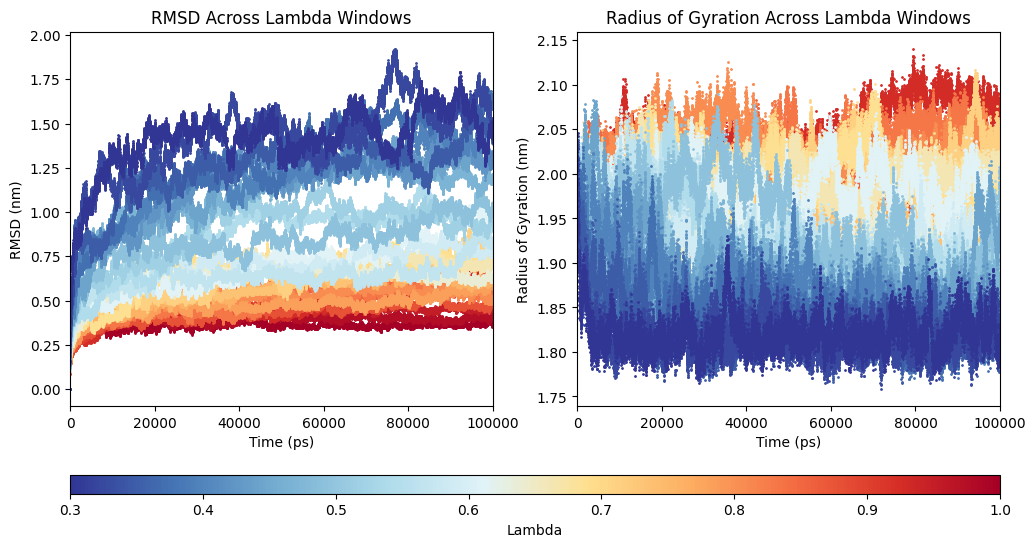

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# LAMBDAS
# =========================================================

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

norm = Normalize(vmin=min(lambdas), vmax=max(lambdas))

main_dir = "2d"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_lambdas = []
valid_labels = []

for lam, label in zip(lambdas, labels):

    rmsd_file = os.path.join(main_dir, f"lambda_{label}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"lambda_{label}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for lambda_{label}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_lambdas.append(lam)
    valid_labels.append(label)

print("Valid lambdas:", valid_labels)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Lambda Windows")
ax1.set_xlim(0, 100000)

# =========================================================
# Rg
# =========================================================

for i, lam in enumerate(valid_lambdas):

    color = CMAP(norm(lam))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Lambda Windows")
ax2.set_xlim(0, 100000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Lambda")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## ⚡ Re-extract Potential Energy After 100 ns

Extracts the **potential-energy time series** for all **30 λ replicas** from the extended **100 ns trajectories**. These updated data are used to re-evaluate **potential-energy overlap between neighboring λ replicas** after longer sampling.

In [11]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  2d/lambda_XXX/topol.edr
#   Output: 2d/lambda_XXX/potential.xvg
# ============================================================

def clean_env():
    for k in list(os.environ):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_cmd(cmd):
    clean_env()
    print(cmd, flush=True)
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(lam):

    label = int(round(lam * 100))
    replica_dir = os.path.join(main_dir, f"lambda_{label}")

    edr_file = os.path.join(replica_dir, "topol.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ lambda_{label}: missing topol.edr"

    print(f"▶️ Starting lambda_{label}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ lambda_{label}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "2d")

lambdas = np.linspace(1.00, 0.30, 30)

# Run all lambda windows at once
max_workers = len(lambdas)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, lam)
        for lam in lambdas
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all lambda windows.")

▶️ Starting lambda_100
▶️ Starting lambda_98
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_100/potential.xvg" -xvg none
▶️ Starting lambda_90
▶️ Starting lambda_86
▶️ Starting lambda_95
▶️ Starting lambda_88
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_90/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_90/potential.xvg" -xvg none
▶️ Starting lambda_83
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr" -o "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/potential.xvg" -xvg none
echo "Potential" | gmx_mpi energy -f "/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_

               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_86/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 50000000 steps [ 0.0000 through 99999.9980 ps ], 1 data sets
All statistics are over 500000 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -499702         25    765.108   -161.609  (kJ/mol)
✅ lambda_86: potential.xvg written, 10001 frames


               :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/potential.xvg -xvg none

Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/3PRG/2d/lambda_98/topol.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  


Statistics over 50000000 steps [ 0.0000 through 99999.9980 ps ], 1 data sets
All statistics are over 500000 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -475310         11     758.68     70.302  (kJ/mol)
✅ lambda_37: potential.xvg written, 10001 frames


...

✅ lambda_42: potential.xvg written, 10001 frames
✅ lambda_61: potential.xvg written, 10180 frames
✅ lambda_90: potential.xvg written, 10001 frames
✅ lambda_76: potential.xvg written, 10001 frames
✅ lambda_81: potential.xvg written, 10001 frames

Statistics over 50370001 steps [ 0.0000 through 100740.0000 ps ], 1 data sets
All statistics are over 503701 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -474166        9.2    759.664    29.5455  (kJ/mol)

Statistics over 50720001 steps [ 0.0000 through 101440.0000 ps ], 1 data sets
All statistics are over 507201 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -471954         11    755.823    48.6654  (kJ/mol)
✅ lambda_35: potential.xvg written, 10075 frames
✅ lambda_30: p

Last energy frame read 10144 time 101440.000         
Reading energy frame   2000 time 20000.000         
GROMACS reminds you: "The aim of science is not to open the door to infinite wisdom, but to set a limit to infinite error." (Bertolt Brecht, Life of Galileo)

Last energy frame read 10074 time 100740.000         
Reading energy frame    400 time 4000.000          
GROMACS reminds you: "The aim of science is not to open the door to infinite wisdom, but to set a limit to infinite error." (Bertolt Brecht, Life of Galileo)

Last energy frame read 10305 time 103050.000         
Reading energy frame   1600 time 16000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10626 time 106260.000         
Reading energy frame   1200 time 12000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10001 time 100000.008         
Reading energy frame   5000 time 50000.000         
GROMACS reminds you: "History 


Statistics over 51525001 steps [ 0.0000 through 103050.0000 ps ], 1 data sets
All statistics are over 515251 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -478863         15    759.464   -66.7329  (kJ/mol)

Statistics over 53130001 steps [ 0.0000 through 106260.0000 ps ], 1 data sets
All statistics are over 531301 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -473046        9.3    756.372   -8.50576  (kJ/mol)
✅ lambda_44: potential.xvg written, 10306 frames

Statistics over 50000003 steps [ 0.0000 through 100000.0040 ps ], 1 data sets
All statistics are over 10002 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
----------------------------------------------------------------

Last energy frame read 10000 time 99999.992         
Reading energy frame   5000 time 50000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10315 time 103150.000         
Reading energy frame   5000 time 50000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10001 time 100000.000         
Reading energy frame   9000 time 90000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10327 time 103270.000         
Reading energy frame   8000 time 80000.000         
GROMACS reminds you: "History has expired" (PubMed Central)

Last energy frame read 10260 time 102600.000         

GROMACS reminds you: "History has expired" (PubMed Central)



✅ lambda_73: potential.xvg written, 10069 frames
✅ lambda_95: potential.xvg written, 10001 frames
✅ lambda_52: potential.xvg written, 10001 frames
✅ lambda_88: potential.xvg written, 10002 frames
✅ lambda_54: potential.xvg written, 10328 frames
✅ lambda_59: potential.xvg written, 10261 frames
✅ lambda_47: potential.xvg written, 10316 frames

🎉 Finished extracting potential energy for all lambda windows.


## ⚡ Re-evaluate Potential-Energy Overlap After 100 ns

Plots the **potential-energy distributions** for all **30 λ replicas** after 100 ns of sampling to reassess **overlap between neighboring λ windows** and determine whether the λ spacing is appropriate for replica exchange.

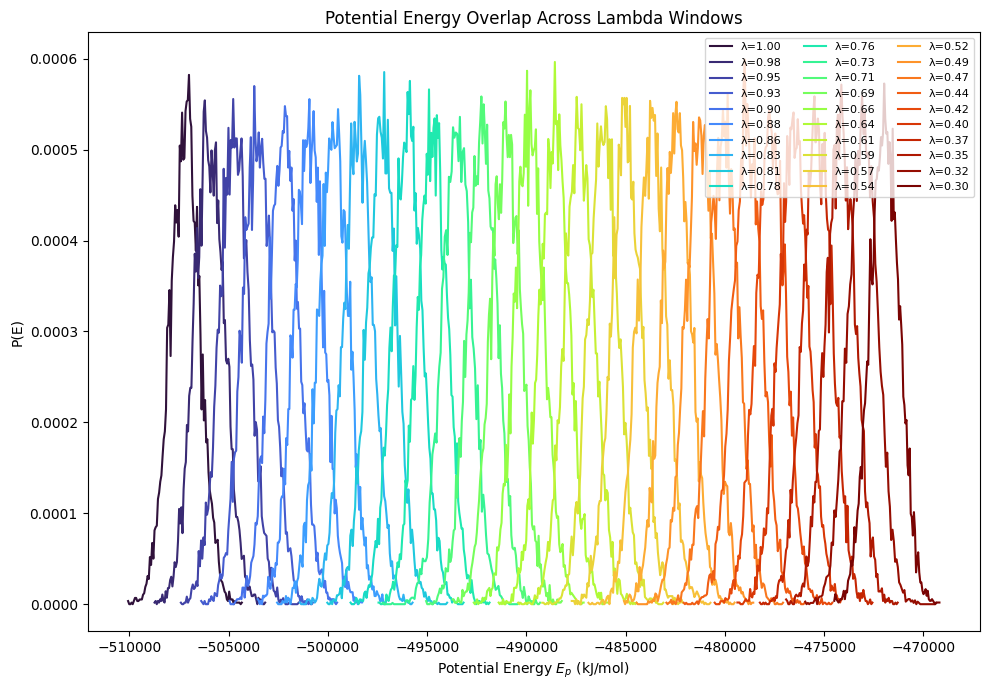

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  2d/lambda_XXX/potential.xvg
# ============================================================

main_dir = "2d"

lambdas = np.linspace(1.00, 0.30, 30)
labels = [int(round(lam * 100)) for lam in lambdas]

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(lambdas)))

plt.figure(figsize=(10, 7))

for i, (lam, label) in enumerate(zip(lambdas, labels)):

    pot_file = os.path.join(main_dir, f"lambda_{label}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"λ={lam:.2f}"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap Across Lambda Windows")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### 🔎 Inference After 100 ns

After 100 ns, the neighboring λ windows show **substantial potential-energy overlap**, supporting the selected λ range and spacing for replica exchange. Increasing tempering progressively broadens the conformational sampling, with the lower λ replicas reaching **RMSD values >1 nm and up to ~2 nm**, while the radius of gyration remains relatively constrained. This is encouraging because the replicas are exploring conformations far from the starting structure without obvious global expansion of the protein. The highly displaced states may therefore represent **intermediate or partially unfolded conformations**, similar to those sampled in the urea and SMOG simulations, although this will require structural analysis to confirm. 

Overall, this test provides a **blueprint for selecting the λ range** for the expanded 64-replica setup with replica exchange. In particular, the RMSD profiles identify the λ regime where sampling begins to cross **~1.5 nm RMSD**, a range associated with the intermediate/partially unfolded conformations observed in the urea and SMOG simulations. This λ range will therefore guide the design of the denser 64-replica ladder to better sample these states.
*******